In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [14]:
df = pd.read_csv('data/Mall_Customers.csv')
#X = df.drop(columns='CustomerID')
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]
#X['Genre'] = X['Genre'].map({'Male':0, 'Female':1})

In [15]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X = pd.DataFrame(data=X_scaled, columns=X.columns)

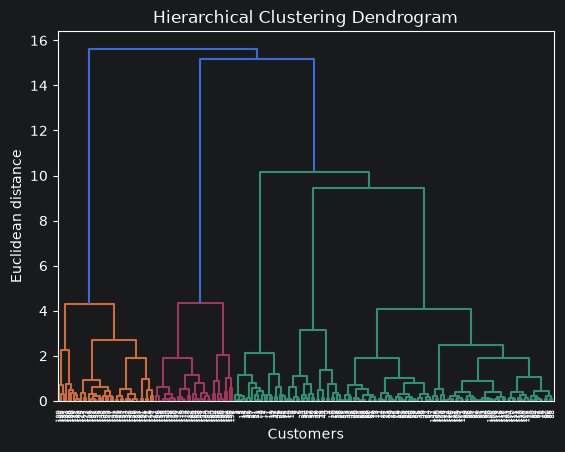

In [16]:
from scipy.cluster.hierarchy import dendrogram, linkage
dendrogram = dendrogram(linkage(X, method='ward'))
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean distance')
plt.show()

In [17]:
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters=3, metric= 'euclidean', linkage='ward')
y_hc = hc.fit_predict(X)

In [18]:
X['Cluster'] = y_hc

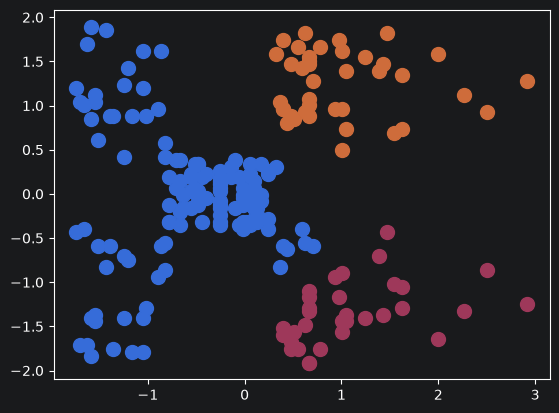

In [19]:
cluster_0 = X[X['Cluster'] == 0]
cluster_1 = X[X['Cluster'] == 1]
cluster_2 = X[X['Cluster'] == 2]
#cluster_3 = X[X['Cluster'] == 3]
#cluster_4 = X[X['Cluster'] == 4]
plt.scatter(cluster_0['Annual Income (k$)'], cluster_0['Spending Score (1-100)'],s = 100,label='Cluster 1')
plt.scatter(cluster_1['Annual Income (k$)'], cluster_1['Spending Score (1-100)'],s = 100,label='Cluster 2')
plt.scatter(cluster_2['Annual Income (k$)'], cluster_2['Spending Score (1-100)'],s = 100,label='Cluster 3')
#plt.scatter(cluster_3['Annual Income (k$)'], cluster_3['Spending Score (1-100)'],s = 100,label='Cluster 4')
#plt.scatter(cluster_4['Annual Income (k$)'],cluster_4['Spending Score (1-100)'],s = 100,label='Cluster 5')